In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/processed/train_features_138.csv")
test = pd.read_csv("../data/processed/test_features_138.csv")

X = train.drop(columns=["id", "target"])
y = train["target"]

X_test = test.drop(columns=["id"])

print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)
print("Classes:", y.nunique())

X: (635, 138)
y: (635,)
X_test: (403, 138)
Classes: 12


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (508, 138)
X_val: (127, 138)
y_train: (508,)
y_val: (127,)


In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (508, 138)
Validation: (127, 138)
Test: (403, 138)


In [4]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=11)

X_train_lda = lda.fit_transform(X_train_scaled, y_train)

X_val_lda = lda.transform(X_val_scaled)
X_test_lda = lda.transform(X_test_scaled)

print("Train:", X_train_lda.shape)
print("Validation:", X_val_lda.shape)
print("Test:", X_test_lda.shape)

Train: (508, 11)
Validation: (127, 11)
Test: (403, 11)


In [5]:
explained_variance_lda = lda.explained_variance_ratio_

cumulative_lda = np.cumsum(explained_variance_lda)

print("Individual explained variance:")
print(explained_variance_lda)

print("\nCumulative explained variance:")
print(cumulative_lda)

Individual explained variance:
[0.545971   0.1655926  0.10900299 0.0808779  0.03057613 0.01947269
 0.01674854 0.01006888 0.00874324 0.00748402 0.00546201]

Cumulative explained variance:
[0.545971   0.7115636  0.82056659 0.90144448 0.93202061 0.9514933
 0.96824184 0.97831073 0.98705397 0.99453799 1.        ]


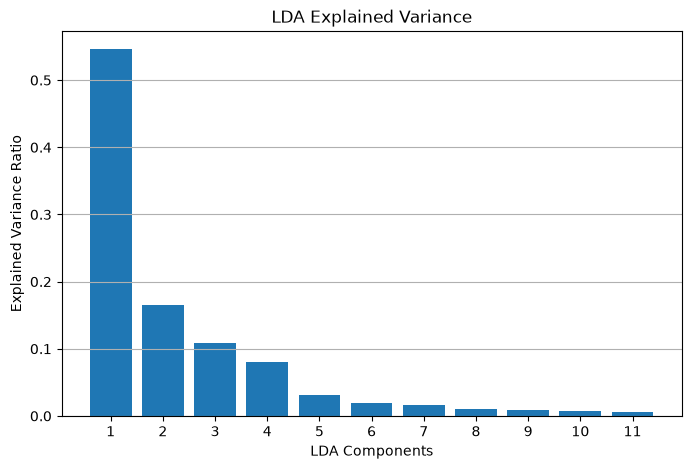

In [6]:
plt.figure(figsize=(8, 5))

plt.bar(
    range(1, len(explained_variance_lda) + 1),
    explained_variance_lda
)

plt.xlabel("LDA Components")
plt.ylabel("Explained Variance Ratio")
plt.title("LDA Explained Variance")
plt.xticks(range(1, 12))
plt.grid(axis="y")
plt.show()

In [8]:
lda_train_df = pd.DataFrame(
    X_train_lda,
    columns=[f"LD{i+1}" for i in range(11)],
    index=X_train.index
)

lda_val_df = pd.DataFrame(
    X_val_lda,
    columns=[f"LD{i+1}" for i in range(11)],
    index=X_val.index
)

lda_test_df = pd.DataFrame(
    X_test_lda,
    columns=[f"LD{i+1}" for i in range(11)]
)

lda_train_df.insert(0, "id", train.loc[X_train.index, "id"])
lda_train_df["target"] = y_train

lda_val_df.insert(0, "id", train.loc[X_val.index, "id"])
lda_val_df["target"] = y_val

lda_test_df.insert(0, "id", test["id"].values)

lda_train_df.to_csv("../experiments/lda/train_lda11.csv", index=False)
lda_val_df.to_csv("../experiments/lda/val_lda11.csv", index=False)
lda_test_df.to_csv("../experiments/lda/test_lda11.csv", index=False)

print(lda_train_df.shape)
print(lda_val_df.shape)
print(lda_test_df.shape)

(508, 13)
(127, 13)
(403, 12)


In [9]:
files = [
    "train_lda11.csv",
    "val_lda11.csv",
    "test_lda11.csv"
]

for file in files:
    path = "../experiments/lda/" + file
    df = pd.read_csv(path)

    print(
        file,
        df.shape,
        "Missing:", df.isna().sum().sum()
    )

train_lda11.csv (508, 13) Missing: 0
val_lda11.csv (127, 13) Missing: 0
test_lda11.csv (403, 12) Missing: 0
